<a href="https://colab.research.google.com/github/MQAZ11/DATA-110-Fall-2026/blob/main/Project_1_Mark_Beavers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 1
## Question: What is the relationship between the number of ground duels won (Player winning or stealing the ball on the ground) and the number of cleansheets (Games with no goals conceded)? Does a player who has more won ground duels end up with more cleansheets in a season?


### Dataset: English Premier League Players Statistics for the 2024/25 Season. Dataset includes stats on 562 players for the 2024/25 season.

[EPL Player Stats 24/25](https://data.scorenetwork.org/soccer/epl-player-stats-2425.html#references)

In [ ]:
import matplotlib.pyplot as plt
import matplotlib as mp
import numpy as np


AllEPL = pd.read_csv('epl_player_stats_24_25(1).csv')

In [ ]:
print(AllEPL.describe())
print(AllEPL.shape)
print(AllEPL.info())

       Appearances      Minutes       Goals     Assists       Shots  \
count   562.000000   562.000000  562.000000  562.000000  562.000000   
mean     20.581851  1336.208185    1.713523    1.145907   17.526690   
std      12.136239  1055.099340    3.310674    2.197891   22.342341   
min       1.000000     1.000000    0.000000    0.000000    0.000000   
25%      10.000000   336.750000    0.000000    0.000000    1.000000   
50%      22.000000  1156.000000    0.000000    0.000000   10.000000   
75%      32.000000  2229.250000    2.000000    2.000000   25.000000   
max      38.000000  3420.000000   29.000000   18.000000  130.000000   

       Shots On Target  Big Chances Missed  Hit Woodwork    Offsides  \
count       562.000000          562.000000    562.000000  562.000000   
mean          5.514235            2.135231      0.496441    2.250890   
std           9.407054            3.732051      0.986986    4.085456   
min           0.000000            0.000000      0.000000    0.000000   


Select only ground duels won and cleansheets

In [ ]:
df = AllEPL[['Player Name','gDuels Won', 'Clean Sheets']] #All data in selected columns
print((df.describe()))
print(df.shape)
print(df.info())


       gDuels Won  Clean Sheets
count  562.000000    562.000000
mean    42.768683      2.170819
std     50.792962      3.040898
min      0.000000      0.000000
25%      0.000000      0.000000
50%     26.000000      1.000000
75%     77.750000      3.000000
max    224.000000     14.000000
(562, 3)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 562 entries, 0 to 561
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Player Name   562 non-null    object
 1   gDuels Won    562 non-null    int64 
 2   Clean Sheets  562 non-null    int64 
dtypes: int64(2), object(1)
memory usage: 13.3+ KB
None


In [ ]:
df50 = np.arange(0 , 50) #Data of top 50 players with most won ground duels.
print(df50)

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49]


Scatter plot with all players

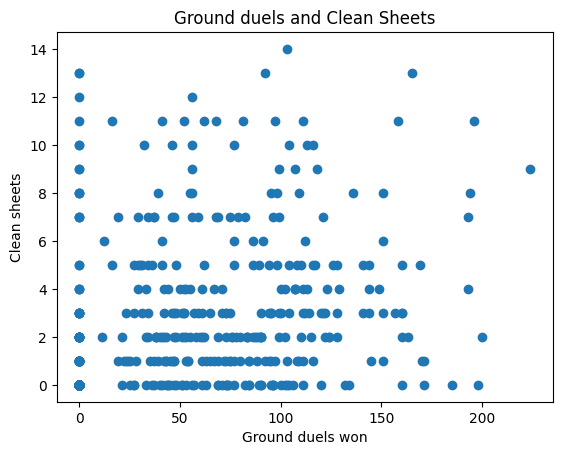

In [ ]:
plt.scatter(df['gDuels Won'], df['Clean Sheets'])
plt.title('Ground duels and Clean Sheets')
plt.xlabel('Ground duels won')
plt.ylabel('Clean sheets')
plt.show()

Scatter plot with top 50 players

In [ ]:
df50 = df.sort_values(by= "gDuels Won", ascending=False) #Data of top 50 players with most won ground duels.
print(df50.head(50))

               Player Name  gDuels Won  Clean Sheets
367        Bruno Fernandes         224             9
525         Mohammed Kudus         200             2
385         Rasmus Højlund         198             0
318        Ibrahima Konaté         196            11
324          Mohamed Salah         194             8
346          Mateo Kovacic         193             4
401              Joelinton         193             7
509          Edson Álvarez         185             0
264           Julio Enciso         171             0
122             Igor Julio         171             1
458       Mateus Fernandes         170             1
107            Yoane Wissa         169             5
431      Nikola Milenkovic         165            13
56          Dango Ouattara         163             2
251        Cameron Burgess         160             0
426     Morgan Gibbs-White         160             3
392         Anthony Gordon         160             2
503      Aaron Wan-Bissaka         160        

Visualization comparing number of ground duels won and number of clean sheets for top 50 players.

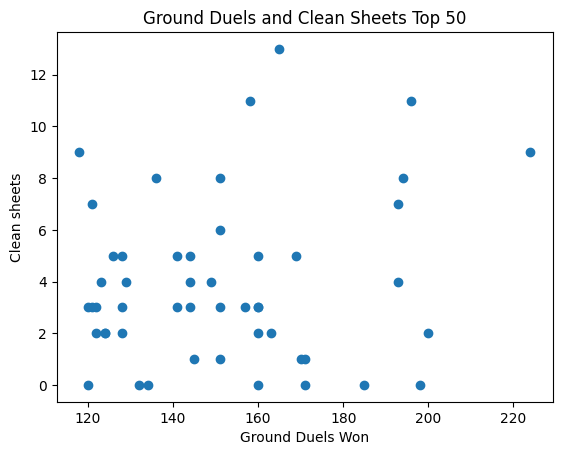

In [ ]:
plt.scatter(df50.head(50)['gDuels Won'], df50.head(50)['Clean Sheets'])
plt.title('Ground Duels and Clean Sheets Top 50')
plt.xlabel('Ground Duels Won')
plt.ylabel('Clean sheets')
plt.show()

Regression line over previous plot

Text(0, 0.5, 'Clean Sheets')

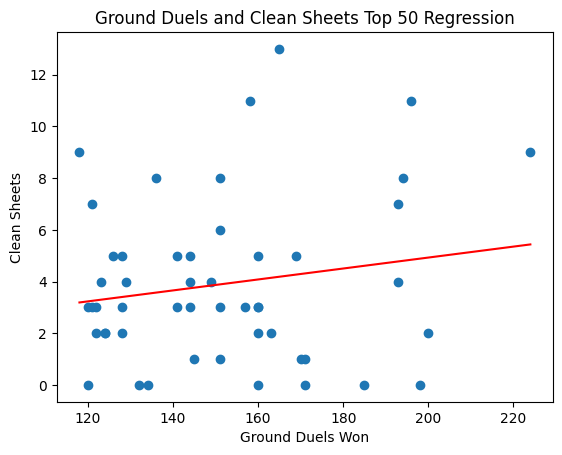

In [ ]:
m, b = np.polyfit(df50.head(50)['gDuels Won'], df50.head(50)['Clean Sheets'], 1)
regression_line = m * np.array(df50.head(50)['gDuels Won']) + b

plt.scatter(df50.head(50)['gDuels Won'], df50.head(50)['Clean Sheets'])
plt.plot(df50.head(50)['gDuels Won'], regression_line,color='red')
plt.title('Ground Duels and Clean Sheets Top 50 Regression')
plt.xlabel('Ground Duels Won')
plt.ylabel('Clean Sheets')